# Smart Recycling Coach: Practical Checkpoint 1

COMP 365 team project. A three-class image classifier (**recycling**, **trash**, **special handling**)
that gives a disposal suggestion from a photo, following the approved Pitch and Roles plan:

1. Build a labeled crop dataset from TACO (Trash Annotations in Context) with a documented label map.
2. Make a 70/15/15 train / validation / test split, keeping crops from the same photo in the same split.
3. Majority-class baseline.
4. Fine-tune MobileNetV3-Large pretrained on ImageNet.
5. Evaluate on held-out images: accuracy, macro F1, per-class report, confusion matrix.
6. `predict()` returns label, confidence and disposal guidance for a new photo.

**How to run:** open in Google Colab, choose *Runtime > Change runtime type > T4 GPU*, then *Runtime > Run all*.
Takes about 15 to 25 minutes, most of it downloading TACO images. Everything is saved in `outputs/`
and zipped at the end.

**Team photos (optional):** upload images to `team_photos/recycling/`, `team_photos/trash/` and
`team_photos/special_handling/` before running and they are added to the dataset with source `team`.

AI assistance: Claude helped write the notebook code. We reviewed the code to be ran in Colab. We checked the report against the outputs.

In [1]:
import os, json, time, random, shutil, io
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LABELS = ["recycling", "trash", "special_handling"]
OUT, RAW, CROPS = Path("outputs"), Path("taco_raw"), Path("crops")
for d in (OUT, RAW, CROPS): d.mkdir(exist_ok=True)
print("torch", torch.__version__, "| device:", DEVICE)

torch 2.11.0+cu130 | device: cuda


## 1. Data: TACO annotations and the three-class label map

TACO has 1,500 photos of litter with 4,784 boxed objects in 60 categories. Each box becomes one crop.
Categories are mapped to our three labels using EPA common-recyclables guidance; categories whose
disposal depends on the item or location (bottle caps, lids, foil, unlabeled litter, other plastic, food
containers) are left out for now and listed for the label-guide review.

In [2]:
# TACO category name -> project label. Categories not listed are excluded as ambiguous.
LABEL_MAP = {
    # recycling: rinsed bottles, cans, jars, clean paper and cardboard (EPA common recyclables)
    "Clear plastic bottle": "recycling", "Other plastic bottle": "recycling", "Glass bottle": "recycling",
    "Glass jar": "recycling", "Drink can": "recycling", "Food Can": "recycling", "Metal lid": "recycling",
    "Corrugated carton": "recycling", "Other carton": "recycling", "Drink carton": "recycling",
    "Egg carton": "recycling", "Toilet tube": "recycling", "Normal paper": "recycling",
    "Magazine paper": "recycling", "Paper bag": "recycling",
    # special handling: hazardous, sharp, or store drop-off items that should not go in either bin
    "Battery": "special_handling", "Aerosol": "special_handling", "Broken glass": "special_handling",
    "Single-use carrier bag": "special_handling", "Polypropylene bag": "special_handling",
    # trash: soiled, multi-layer, film, foam, and small items not accepted in curbside recycling
    "Cigarette": "trash", "Plastic film": "trash", "Other plastic wrapper": "trash", "Crisp packet": "trash",
    "Plastic straw": "trash", "Paper straw": "trash", "Styrofoam piece": "trash", "Foam cup": "trash",
    "Foam food container": "trash", "Tissues": "trash", "Paper cup": "trash", "Disposable plastic cup": "trash",
    "Plastic utensils": "trash", "Food waste": "trash", "Rope & strings": "trash", "Plastic glooves": "trash",
    "Squeezable tube": "trash", "Six pack rings": "trash", "Garbage bag": "trash",
    "Aluminium blister pack": "trash", "Carded blister pack": "trash",
}

ann = requests.get("https://raw.githubusercontent.com/pedropro/TACO/master/data/annotations.json", timeout=60).json()
cats = {c["id"]: c["name"] for c in ann["categories"]}
imgs = {i["id"]: i for i in ann["images"]}
print(f"TACO: {len(ann['images'])} photos, {len(ann['annotations'])} objects, {len(cats)} categories")

MIN_SIDE = 48   # px in the original photo; smaller boxes are too blurry to classify
rows, excluded = [], {}
for a in ann["annotations"]:
    name = cats[a["category_id"]]
    label = LABEL_MAP.get(name)
    if label is None:
        excluded[name] = excluded.get(name, 0) + 1; continue
    x, y, w, h = a["bbox"]
    if min(w, h) < MIN_SIDE: continue
    im = imgs[a["image_id"]]
    rows.append({"crop_id": f"taco_{a['id']}", "source": "taco", "group": f"taco_img_{a['image_id']}",
                 "taco_category": name, "label": label, "url": im["flickr_url"],
                 "raw_file": im["file_name"].replace("/", "_"), "bbox": [x, y, w, h]})
df_all = pd.DataFrame(rows)
print("Excluded (ambiguous) categories:", dict(sorted(excluded.items(), key=lambda t: -t[1])))
print("\nUsable crops before balancing:")
print(df_all.label.value_counts().reindex(LABELS))

TACO: 1500 photos, 4784 objects, 60 categories
Excluded (ambiguous) categories: {'Unlabeled litter': 517, 'Other plastic': 273, 'Plastic bottle cap': 209, 'Pop tab': 99, 'Metal bottle cap': 80, 'Plastic lid': 77, 'Aluminium foil': 62, 'Disposable food container': 38, 'Meal carton': 30, 'Scrap metal': 20, 'Wrapping paper': 12, 'Spread tub': 9, 'Shoe': 7, 'Glass cup': 6, 'Other plastic container': 6, 'Tupperware': 4, 'Pizza box': 3, 'Other plastic cup': 2}

Usable crops before balancing:
label
recycling           1018
trash               1463
special_handling     130
Name: count, dtype: int64


**Balancing.** Trash and recycling have far more TACO crops than special handling. We cap the two large
classes at `CAP` crops each (random, seeded) so training time stays short and the classes are closer in size,
and we use class-weighted loss for the remaining imbalance.

In [3]:
CAP = 450
parts = []
for lab, g in df_all.groupby("label"):
    parts.append(g.sample(min(len(g), CAP), random_state=SEED) if lab != "special_handling" else g)
df = pd.concat(parts).reset_index(drop=True)

# optional team photos
team_rows = []
for lab in LABELS:
    for p in sorted(Path("team_photos", lab).glob("*")) if Path("team_photos", lab).exists() else []:
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            team_rows.append({"crop_id": f"team_{lab}_{p.stem}", "source": "team", "group": f"team_{p.stem}",
                              "taco_category": "", "label": lab, "url": "", "raw_file": str(p), "bbox": None})
if team_rows:
    df = pd.concat([df, pd.DataFrame(team_rows)], ignore_index=True)
print(pd.crosstab(df.label, df.source, margins=True).reindex(LABELS + ["All"]))

source            taco   All
label                       
recycling          450   450
trash              450   450
special_handling   130   130
All               1030  1030


## 2. Download photos and cut crops

In [4]:
def fetch(row):
    dst = RAW / row["raw_file"]
    if dst.exists(): return True
    for attempt in range(3):
        try:
            r = requests.get(row["url"], timeout=60)
            if r.ok and len(r.content) > 1000:
                dst.write_bytes(r.content); return True
        except requests.RequestException:
            time.sleep(2)
    return False

need = df[df.source == "taco"].drop_duplicates("raw_file")
t0 = time.time()
with ThreadPoolExecutor(16) as ex:
    ok = list(ex.map(fetch, need.to_dict("records")))
print(f"Downloaded {sum(ok)}/{len(need)} photos in {time.time() - t0:.0f}s")

def make_crop(row, pad=0.10):
    dst = CROPS / row["label"] / f"{row['crop_id']}.jpg"
    if dst.exists(): return str(dst)
    dst.parent.mkdir(parents=True, exist_ok=True)
    try:
        if row["source"] == "team":
            im = ImageOps.exif_transpose(Image.open(row["raw_file"])).convert("RGB")
        else:
            im = ImageOps.exif_transpose(Image.open(RAW / row["raw_file"])).convert("RGB")
            x, y, w, h = row["bbox"]
            # TACO boxes are in the stored (un-rotated) pixel frame; skip if EXIF rotation changed the frame
            if (im.width, im.height) != (imgs_by_file[row["raw_file"]]["width"], imgs_by_file[row["raw_file"]]["height"]):
                im = Image.open(RAW / row["raw_file"]).convert("RGB")
            px, py = w * pad, h * pad
            im = im.crop((max(0, x - px), max(0, y - py), min(im.width, x + w + px), min(im.height, y + h + py)))
        im.thumbnail((448, 448))
        im.save(dst, quality=92)
        return str(dst)
    except Exception as e:
        return None

imgs_by_file = {i["file_name"].replace("/", "_"): i for i in ann["images"]}
df["path"] = [make_crop(r) for r in df.to_dict("records")]
missing = df.path.isna().sum()
df = df.dropna(subset=["path"]).reset_index(drop=True)
print(f"Crops ready: {len(df)}  (failed: {missing})")

Downloaded 662/662 photos in 18s
Crops ready: 1030  (failed: 0)


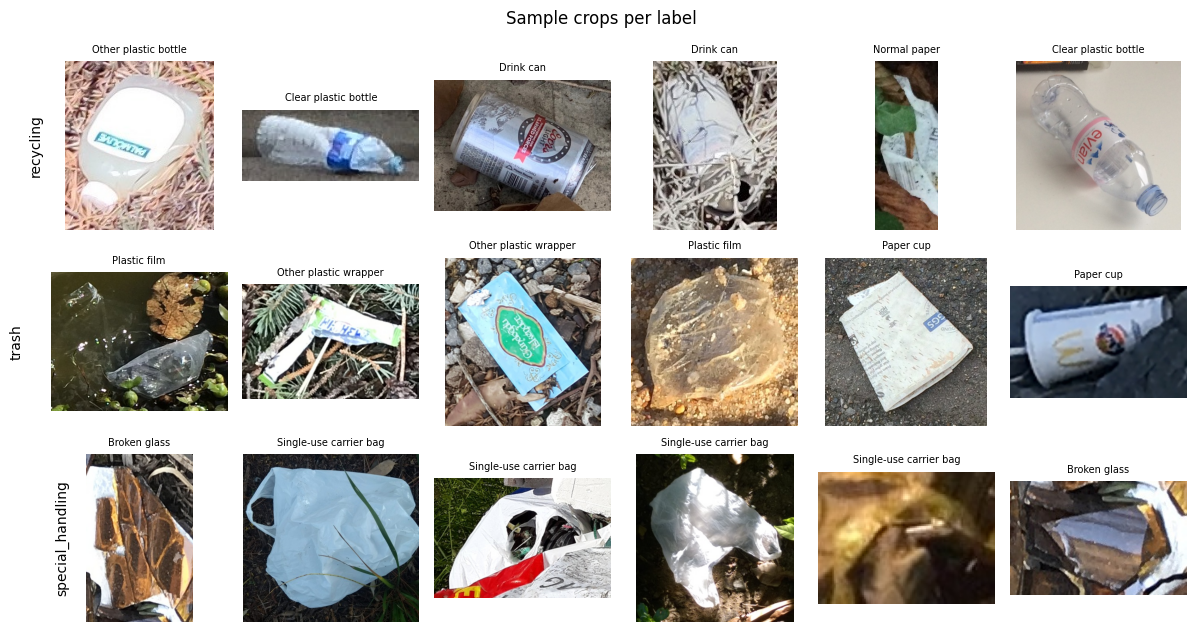

In [5]:
fig, axes = plt.subplots(3, 6, figsize=(12, 6.4))
for r, lab in enumerate(LABELS):
    sub = df[df.label == lab].sample(6, random_state=SEED)
    for ax, (_, row) in zip(axes[r], sub.iterrows()):
        ax.imshow(Image.open(row.path)); ax.axis("off")
        ax.set_title(row.taco_category or "team photo", fontsize=7)
    axes[r][0].text(-0.15, 0.5, lab, transform=axes[r][0].transAxes, rotation=90, va="center", ha="right", fontsize=10)
plt.suptitle("Sample crops per label"); plt.tight_layout(); plt.savefig(OUT / "sample_crops.png", dpi=150); plt.show()

## 3. Group-aware 70 / 15 / 15 split

split             train  val  test
label                             
recycling           337   52    61
trash               324   64    62
special_handling     86   18    26
total               747  134   149


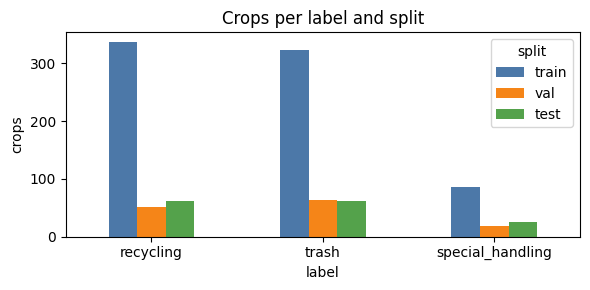

In [6]:
# 20 stratified folds grouped by source photo: 3 folds test, 3 folds validation, 14 folds train.
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
fold = np.zeros(len(df), dtype=int)
for k, (_, idx) in enumerate(sgkf.split(df, df.label, df.group)):
    fold[idx] = k
df["split"] = np.where(fold < 3, "test", np.where(fold < 6, "val", "train"))
assert df.groupby("group").split.nunique().max() == 1, "a photo leaked across splits"
df.drop(columns=["bbox"]).to_csv(OUT / "split_manifest.csv", index=False)
counts = pd.crosstab(df.label, df.split).reindex(index=LABELS, columns=["train", "val", "test"])
counts.loc["total"] = counts.sum()
print(counts)

fig, ax = plt.subplots(figsize=(6, 3))
counts.drop("total").plot.bar(ax=ax, rot=0, color=["#4C78A8", "#F58518", "#54A24B"])
ax.set_ylabel("crops"); ax.set_title("Crops per label and split"); plt.tight_layout()
plt.savefig(OUT / "split_counts.png", dpi=150); plt.show()

## 4. Majority-class baseline

In [7]:
def scores(y_true, y_pred):
    return {"accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
            "macro_f1": round(float(f1_score(y_true, y_pred, average="macro", labels=range(len(LABELS)))), 4)}

y_idx = df.label.map(LABELS.index).values
tr, va, te = (np.where(df.split == s)[0] for s in ("train", "val", "test"))
majority = int(np.bincount(y_idx[tr]).argmax())
results = {"majority_baseline": {"predicts": LABELS[majority],
                                 "val": scores(y_idx[va], np.full(len(va), majority)),
                                 "test": scores(y_idx[te], np.full(len(te), majority))}}
print(json.dumps(results["majority_baseline"], indent=2))

{
  "predicts": "recycling",
  "val": {
    "accuracy": 0.3881,
    "macro_f1": 0.1864
  },
  "test": {
    "accuracy": 0.4094,
    "macro_f1": 0.1937
  }
}


## 5. Fine-tune MobileNetV3-Large (ImageNet weights)

In [8]:
weights = models.MobileNet_V3_Large_Weights.IMAGENET1K_V2
norm = transforms.Normalize(weights.transforms().mean, weights.transforms().std)
train_tf = transforms.Compose([transforms.RandomResizedCrop(224, scale=(0.6, 1.0)), transforms.RandomHorizontalFlip(),
                               transforms.RandomRotation(15), transforms.ColorJitter(0.3, 0.3, 0.3),
                               transforms.ToTensor(), norm])
eval_tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(), norm])

class Crops(Dataset):
    def __init__(self, idx, tf): self.idx, self.tf = idx, tf
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        return self.tf(Image.open(df.path[j]).convert("RGB")), y_idx[j]

BS = 32
dl_tr = DataLoader(Crops(tr, train_tf), batch_size=BS, shuffle=True, num_workers=2)
dl_va = DataLoader(Crops(va, eval_tf), batch_size=BS, num_workers=2)
dl_te = DataLoader(Crops(te, eval_tf), batch_size=BS, num_workers=2)

model = models.mobilenet_v3_large(weights=weights)
model.classifier[3] = nn.Linear(model.classifier[3].in_features, len(LABELS))
model = model.to(DEVICE)

cw = torch.tensor(len(tr) / (len(LABELS) * np.bincount(y_idx[tr], minlength=len(LABELS))), dtype=torch.float32)
loss_fn = nn.CrossEntropyLoss(weight=cw.to(DEVICE))
EPOCHS = 10
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)

@torch.no_grad()
def run_eval(dl):
    model.eval(); probs = []
    for xb, _ in dl:
        probs.append(torch.softmax(model(xb.to(DEVICE)), 1).cpu())
    return torch.cat(probs).numpy()

history, best_f1 = [], -1
for ep in range(1, EPOCHS + 1):
    model.train(); t0, tot = time.time(), 0.0
    for xb, yb in dl_tr:
        opt.zero_grad()
        loss = loss_fn(model(xb.to(DEVICE)), yb.to(DEVICE))
        loss.backward(); opt.step(); tot += loss.item() * len(yb)
    sched.step()
    vs = scores(y_idx[va], run_eval(dl_va).argmax(1))
    history.append({"epoch": ep, "train_loss": round(tot / len(tr), 4), **{f"val_{k}": v for k, v in vs.items()}})
    print(f"epoch {ep:2d}  loss {tot / len(tr):.3f}  val acc {vs['accuracy']:.3f}  val macro-F1 {vs['macro_f1']:.3f}  ({time.time() - t0:.0f}s)")
    if vs["macro_f1"] > best_f1:
        best_f1 = vs["macro_f1"]
        torch.save({"state_dict": model.state_dict(), "labels": LABELS, "epoch": ep}, OUT / "mobilenetv3_best.pt")

pd.DataFrame(history).to_csv(OUT / "training_history.csv", index=False)
ckpt = torch.load(OUT / "mobilenetv3_best.pt", map_location=DEVICE)
model.load_state_dict(ckpt["state_dict"])
print(f"Best checkpoint: epoch {ckpt['epoch']} (val macro-F1 {best_f1:.3f})")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 185MB/s]


epoch  1  loss 0.986  val acc 0.657  val macro-F1 0.549  (8s)
epoch  2  loss 0.630  val acc 0.664  val macro-F1 0.648  (5s)
epoch  3  loss 0.448  val acc 0.709  val macro-F1 0.711  (6s)
epoch  4  loss 0.309  val acc 0.672  val macro-F1 0.684  (5s)
epoch  5  loss 0.226  val acc 0.724  val macro-F1 0.720  (5s)
epoch  6  loss 0.165  val acc 0.754  val macro-F1 0.761  (5s)
epoch  7  loss 0.131  val acc 0.716  val macro-F1 0.714  (5s)
epoch  8  loss 0.102  val acc 0.746  val macro-F1 0.737  (5s)
epoch  9  loss 0.083  val acc 0.761  val macro-F1 0.752  (5s)
epoch 10  loss 0.090  val acc 0.769  val macro-F1 0.766  (5s)
Best checkpoint: epoch 10 (val macro-F1 0.766)


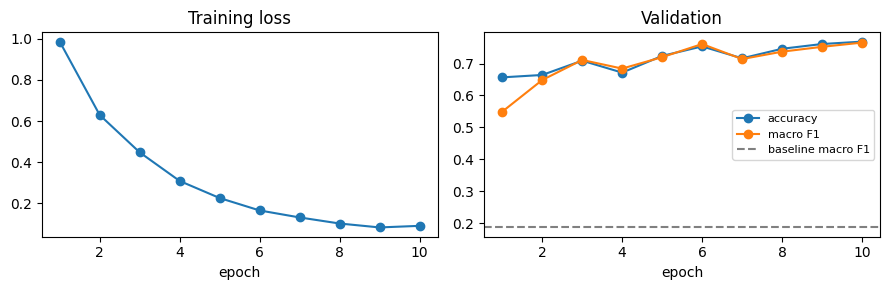

In [9]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(h.epoch, h.train_loss, marker="o"); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(h.epoch, h.val_accuracy, marker="o", label="accuracy"); ax[1].plot(h.epoch, h.val_macro_f1, marker="o", label="macro F1")
ax[1].axhline(results["majority_baseline"]["val"]["macro_f1"], ls="--", c="gray", label="baseline macro F1")
ax[1].set_title("Validation"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "training_curves.png", dpi=150); plt.show()

## 6. Held-out test evaluation

                  precision    recall  f1-score   support

       recycling      0.650     0.852     0.738        61
           trash      0.679     0.613     0.644        62
special_handling      0.846     0.423     0.564        26

        accuracy                          0.678       149
       macro avg      0.725     0.629     0.649       149
    weighted avg      0.696     0.678     0.668       149



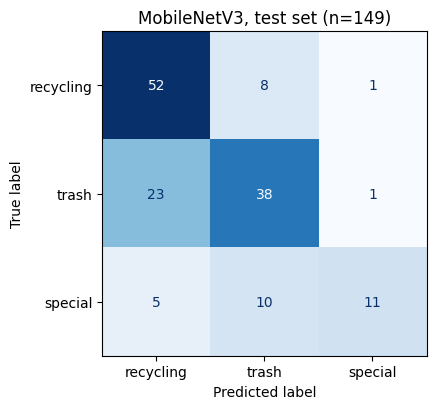

                       accuracy  macro_f1
majority_baseline        0.4094    0.1937
mobilenetv3_finetuned    0.6779    0.6486

Most common test errors by TACO category:
taco_category           label             predicted
Other plastic wrapper   trash             recycling    13
Single-use carrier bag  special_handling  trash         6
Plastic film            trash             recycling     5
Broken glass            special_handling  trash         4
                                          recycling     4
Paper bag               recycling         trash         3
Crisp packet            trash             recycling     2
Other carton            recycling         trash         2
dtype: int64


In [10]:
p_te = run_eval(dl_te); pred = p_te.argmax(1)
results["mobilenetv3_finetuned"] = {"best_epoch": int(ckpt["epoch"]), "val": {"accuracy": h.val_accuracy.iloc[ckpt["epoch"] - 1], "macro_f1": best_f1},
                                    "test": scores(y_idx[te], pred)}
print(classification_report(y_idx[te], pred, labels=range(len(LABELS)), target_names=LABELS, digits=3))
results["per_class_test"] = classification_report(y_idx[te], pred, labels=range(len(LABELS)), target_names=LABELS, output_dict=True)

cm = confusion_matrix(y_idx[te], pred, labels=range(len(LABELS)))
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay(cm, display_labels=["recycling", "trash", "special"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"MobileNetV3, test set (n={len(te)})"); plt.tight_layout()
plt.savefig(OUT / "confusion_matrix.png", dpi=150); plt.show()

comp = pd.DataFrame({m: results[m]["test"] for m in ["majority_baseline", "mobilenetv3_finetuned"]}).T
print(comp)

# prediction table for error analysis (Rickey / Premajyoti)
pt = df.iloc[te][["crop_id", "source", "taco_category", "label", "path"]].copy()
pt["predicted"] = [LABELS[k] for k in pred]; pt["confidence"] = p_te.max(1).round(3)
pt.to_csv(OUT / "test_predictions.csv", index=False)
print("\nMost common test errors by TACO category:")
print(pt[pt.label != pt.predicted].groupby(["taco_category", "label", "predicted"]).size().sort_values(ascending=False).head(8))

## 7. `predict()`: disposal suggestion for one photo

Guidance text is general (EPA) and does not replace campus policy. Predictions under 60% confidence
are flagged so the user checks the bin signage instead of trusting a guess.

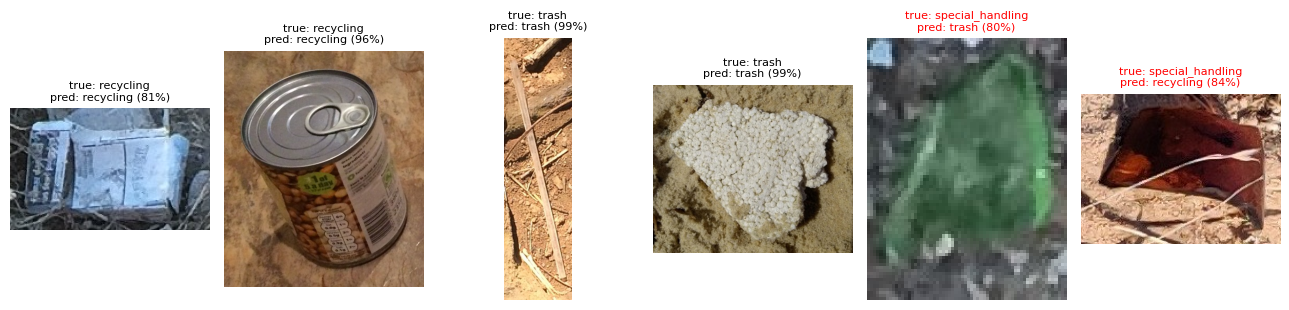

{
  "label": "recycling",
  "confidence": 0.814,
  "all_scores": {
    "recycling": 0.814,
    "trash": 0.186,
    "special_handling": 0.0
  },
  "guidance": "Recycling bin: empty and rinse; flatten cardboard.",
  "true": "recycling",
  "crop_id": "taco_4304"
}


In [11]:
GUIDANCE = {
    "recycling": "Recycling bin: empty and rinse; flatten cardboard.",
    "trash": "Trash bin: not accepted in curbside recycling.",
    "special_handling": "Special handling: do not bin. Batteries/aerosols to hazardous-waste drop-off, wrap broken glass, plastic bags to store drop-off.",
}

@torch.no_grad()
def predict(image, threshold=0.6):
    img = image if isinstance(image, Image.Image) else ImageOps.exif_transpose(Image.open(image))
    model.eval()
    p = torch.softmax(model(eval_tf(img.convert("RGB"))[None].to(DEVICE)), 1)[0].cpu().numpy()
    k = int(p.argmax())
    return {"label": LABELS[k], "confidence": round(float(p[k]), 3),
            "all_scores": {l: round(float(s), 3) for l, s in zip(LABELS, p)},
            "guidance": GUIDANCE[LABELS[k]] if p[k] >= threshold else "Not sure: check the bin signage or ask staff."}

rng = np.random.default_rng(SEED)
demo = np.concatenate([rng.choice(te[y_idx[te] == k], 2, replace=False) for k in range(len(LABELS))])
fig, axes = plt.subplots(1, 6, figsize=(13, 3.2)); samples = []
for ax, j in zip(axes, demo):
    r = predict(df.path[j]); r["true"] = df.label[j]; r["crop_id"] = df.crop_id[j]; samples.append(r)
    ax.imshow(Image.open(df.path[j])); ax.axis("off")
    ax.set_title(f"true: {r['true']}\npred: {r['label']} ({r['confidence']:.0%})", fontsize=8,
                 color="black" if r["label"] == r["true"] else "red")
plt.tight_layout(); plt.savefig(OUT / "sample_predictions.png", dpi=150); plt.show()
results["sample_predictions"] = samples
print(json.dumps(samples[0], indent=2))

Try your own photo: upload it in the Colab file pane and set the path below.

In [12]:
MY_PHOTO = "my_photo.jpg"
if Path(MY_PHOTO).exists():
    print(json.dumps(predict(MY_PHOTO), indent=2))

## 8. Save results

In [13]:
results["data"] = {"source": "TACO annotations.json (github.com/pedropro/TACO) + optional team photos",
                   "min_box_side_px": MIN_SIDE, "cap_per_large_class": CAP, "n_crops": int(len(df)),
                   "by_label_and_split": counts.to_dict(), "excluded_categories": excluded}
results["environment"] = {"torch": torch.__version__, "device": DEVICE,
                          "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None}
with open(OUT / "results.json", "w") as f:
    json.dump(results, f, indent=2, default=str)
shutil.make_archive("checkpoint1_outputs", "zip", OUT)
print(json.dumps({k: results[k]["test"] for k in ["majority_baseline", "mobilenetv3_finetuned"]}, indent=2))
print("Saved outputs/ and checkpoint1_outputs.zip")
try:
    from google.colab import files; files.download("checkpoint1_outputs.zip")
except ImportError:
    pass

{
  "majority_baseline": {
    "accuracy": 0.4094,
    "macro_f1": 0.1937
  },
  "mobilenetv3_finetuned": {
    "accuracy": 0.6779,
    "macro_f1": 0.6486
  }
}
Saved outputs/ and checkpoint1_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>